In [1]:

# AgentWeather - API Exploration
# Purpose: Explore weather API data for Karachi

import sys
import pandas as pd
import numpy as np
import matplotlib
import requests
from pathlib import Path
import os
from dotenv import load_dotenv



# Read the OpenWeather API key
api_key = os.getenv("OPENWEATHER_API_KEY")

# Project paths
project_root = Path.cwd().parent

output_dir = project_root / "reports" / "eda"
output_dir.mkdir(parents=True, exist_ok=True)

# Load environment variables from the project root
load_dotenv(project_root / ".env")

# Check whether the key is available
if api_key:
    print("OpenWeather API key loaded successfully!")
else:
    print("API key not found. Check your .env file.")
print("Project root:", project_root)
print("EDA output directory:", output_dir)
print("Python Version:", sys.version)
print("Python Executable:", sys.executable)
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)
print("Matplotlib Version:", matplotlib.__version__)
print("Requests Version:", requests.__version__)

OpenWeather API key loaded successfully!
Project root: /home/musman/Desktop/ShinePearl/AgentWeather
EDA output directory: /home/musman/Desktop/ShinePearl/AgentWeather/reports/eda
Python Version: 3.11.18 (main, Oct 26 2026, 18:19:35) [GCC 14.3.0]
Python Executable: /home/musman/anaconda3/envs/agentweather/bin/python
Pandas Version: 3.1.1
NumPy Version: 2.4.6
Matplotlib Version: 3.11.2
Requests Version: 2.34.2


In [2]:
url = "https://api.open-meteo.com/v1/forecast"

params = {
    "latitude": 24.86,
    "longitude": 67.01,
    "hourly": "uv_index,is_day",
    "timezone": "UTC",
    "forecast_days": 2,
}

response = requests.get(url, params=params, timeout=30)

response.raise_for_status()

data = response.json()

print("API request successful!")
print(data.keys())

API request successful!
dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])


In [3]:
print("Available hourly variables:")
print(data["hourly"].keys())

print("\nFirst 5 timestamps:")
print(data["hourly"]["time"][:5])

print("\nFirst 5 UV index values:")
print(data["hourly"]["uv_index"][:5])

print("\nFirst 5 day/night indicators:")
print(data["hourly"]["is_day"][:5])

Available hourly variables:
dict_keys(['time', 'uv_index', 'is_day'])

First 5 timestamps:
['2026-11-27T00:00', '2026-11-27T01:00', '2026-11-27T02:00', '2026-11-27T03:00', '2026-11-27T04:00']

First 5 UV index values:
[0.0, 0.0, 0.0, 0.3, 1.3]

First 5 day/night indicators:
[0, 0, 1, 1, 1]


In [4]:
df = pd.DataFrame(data["hourly"])

df["time"] = pd.to_datetime(df["time"], utc=True)

df = df.set_index("time")

df.head()

,uv_index,is_day
time,,
2026-11-27 00:00:00+00:00,0.0,0
2026-11-27 01:00:00+00:00,0.0,0
2026-11-27 02:00:00+00:00,0.0,1
2026-11-27 03:00:00+00:00,0.3,1
2026-11-27 04:00:00+00:00,1.3,1


In [5]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 48 entries, 2026-11-27 00:00:00+00:00 to 2026-11-28 23:00:00+00:00
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   uv_index  48 non-null     float64
 1   is_day    48 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 1.1 KB


In [6]:
df.isnull().sum()

uv_index    0
is_day      0
dtype: int64

In [7]:
df.describe()

,uv_index,is_day
count,48.000000,48.000000
mean,1.195833,0.458333
std,1.753896,0.503534
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,2.262500,1.000000
max,4.900000,1.000000


Plot saved successfully!


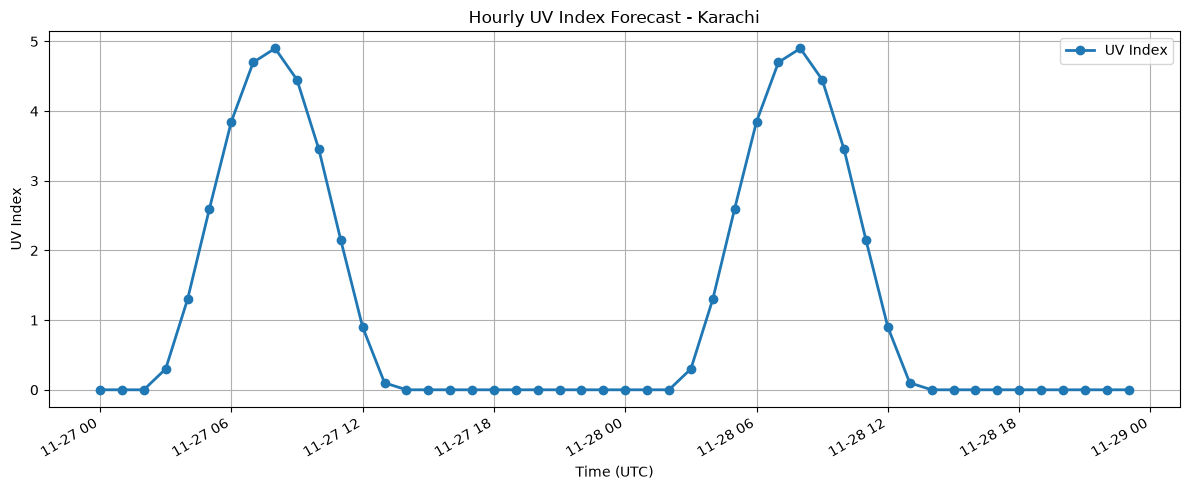

In [8]:

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df.index,
    df["uv_index"],
    marker="o",
    linewidth=2,
    label="UV Index"
)

ax.set_title("Hourly UV Index Forecast - Karachi")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("UV Index")

ax.grid(True)
ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    output_dir / "uv_index_karachi.png",
    dpi=150,
    bbox_inches="tight"
)

print("Plot saved successfully!")

plt.show()

In [9]:
# Expanded weather API request

weather_params = {
    "latitude": 24.86,
    "longitude": 67.01,
    "hourly": (
        "temperature_2m,"
        "relative_humidity_2m,"
        "precipitation,"
        "precipitation_probability,"
        "wind_speed_10m,"
        "wind_direction_10m,"
        "uv_index,"
        "is_day"
    ),
    "temperature_unit": "celsius",
    "wind_speed_unit": "kmh",
    "precipitation_unit": "mm",
    "timezone": "UTC",
    "forecast_days": 2,
}

weather_response = requests.get(
    url,
    params=weather_params,
    timeout=30
)

weather_response.raise_for_status()

weather_data = weather_response.json()

print("Expanded weather API request successful!")
print("Available sections:", weather_data.keys())

Expanded weather API request successful!
Available sections: dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])


In [10]:
print("Available hourly variables")
print(weather_data["hourly"].keys())

print("\nUnits of each variables")
print(weather_data["hourly_units"])

Available hourly variables
dict_keys(['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'precipitation_probability', 'wind_speed_10m', 'wind_direction_10m', 'uv_index', 'is_day'])

Units of each variables
{'time': 'iso8601', 'temperature_2m': '°C', 'relative_humidity_2m': '%', 'precipitation': 'mm', 'precipitation_probability': '%', 'wind_speed_10m': 'km/h', 'wind_direction_10m': '°', 'uv_index': '', 'is_day': ''}


In [11]:
hourly_data = weather_data["hourly"]

print("Number of timestamps:", len(hourly_data["time"]))

for column, values in hourly_data.items():
    print(f"{column}: {len(values)} values")


Number of timestamps: 48
time: 48 values
temperature_2m: 48 values
relative_humidity_2m: 48 values
precipitation: 48 values
precipitation_probability: 48 values
wind_speed_10m: 48 values
wind_direction_10m: 48 values
uv_index: 48 values
is_day: 48 values


In [12]:
weather_df = pd.DataFrame(weather_data["hourly"])

# Convert time strings into proper UTC datetime values
weather_df["time"] = pd.to_datetime(
    weather_df["time"],
    utc=True
)

# Use time as the DataFrame index
weather_df = weather_df.set_index("time")

# Display the first 5 records

weather_df.head()

,temperature_2m,relative_humidity_2m,precipitation,precipitation_probability,wind_speed_10m,wind_direction_10m,uv_index,is_day
time,,,,,,,,
2026-11-27 00:00:00+00:00,19.9,93,0.0,0,4.5,16,0.0,0
2026-11-27 01:00:00+00:00,19.4,93,0.0,0,5.2,12,0.0,0
2026-11-27 02:00:00+00:00,19.0,93,0.0,0,4.7,7,0.0,1
2026-11-27 03:00:00+00:00,19.9,87,0.0,0,3.6,9,0.3,1
2026-11-27 04:00:00+00:00,22.7,74,0.0,0,2.7,4,1.3,1


In [13]:
weather_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 48 entries, 2026-11-27 00:00:00+00:00 to 2026-11-28 23:00:00+00:00
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   temperature_2m             48 non-null     float64
 1   relative_humidity_2m       48 non-null     int64  
 2   precipitation              48 non-null     float64
 3   precipitation_probability  48 non-null     int64  
 4   wind_speed_10m             48 non-null     float64
 5   wind_direction_10m         48 non-null     int64  
 6   uv_index                   48 non-null     float64
 7   is_day                     48 non-null     int64  
dtypes: float64(4), int64(4)
memory usage: 3.4 KB


In [14]:
weather_df.isnull().sum()

temperature_2m               0
relative_humidity_2m         0
precipitation                0
precipitation_probability    0
wind_speed_10m               0
wind_direction_10m           0
uv_index                     0
is_day                       0
dtype: int64

In [15]:
# Check timestamp ordering
print("Timestamps are sorted:", weather_df.index.is_monotonic_increasing)

# Check duplicate timestamps
print("Duplicate timestamps:", weather_df.index.duplicated().sum())

# Check missing values
print("\nMissing values:")
print(weather_df.isnull().sum())

# Check numerical statistics
print("\nStatistical summary:")
weather_df.describe()

Timestamps are sorted: True
Duplicate timestamps: 0

Missing values:
temperature_2m               0
relative_humidity_2m         0
precipitation                0
precipitation_probability    0
wind_speed_10m               0
wind_direction_10m           0
uv_index                     0
is_day                       0
dtype: int64

Statistical summary:


,temperature_2m,relative_humidity_2m,precipitation,precipitation_probability,wind_speed_10m,wind_direction_10m,uv_index,is_day
count,48.000000,48.000000,48.0,48.0,48.000000,48.000000,48.000000,48.000000
mean,24.587500,56.250000,0.0,0.0,7.939583,146.250000,1.195833,0.458333
std,3.613075,28.876479,0.0,0.0,2.512500,128.583196,1.753896,0.503534
min,19.000000,14.000000,0.0,0.0,1.500000,4.000000,0.000000,0.000000
25%,21.550000,28.500000,0.0,0.0,6.275000,39.000000,0.000000,0.000000
50%,24.250000,62.000000,0.0,0.0,8.050000,83.000000,0.000000,0.000000
75%,27.475000,85.250000,0.0,0.0,9.900000,261.250000,2.262500,1.000000
max,31.200000,93.000000,0.0,0.0,12.300000,356.000000,4.900000,1.000000


In [16]:
# Count unique values in each column
unique_counts = weather_df.nunique()

print("Unique values per column:")
print(unique_counts)

# Identify columns with only one unique value
constant_columns = unique_counts[unique_counts == 1]

print("\nConstant columns:")
print(constant_columns)

Unique values per column:
temperature_2m               42
relative_humidity_2m         35
precipitation                 1
precipitation_probability     1
wind_speed_10m               40
wind_direction_10m           42
uv_index                     12
is_day                        2
dtype: int64

Constant columns:
precipitation                1
precipitation_probability    1
dtype: int64


Plot saved successfully: /home/musman/Desktop/ShinePearl/AgentWeather/reports/eda/weather_overview_karachi.png


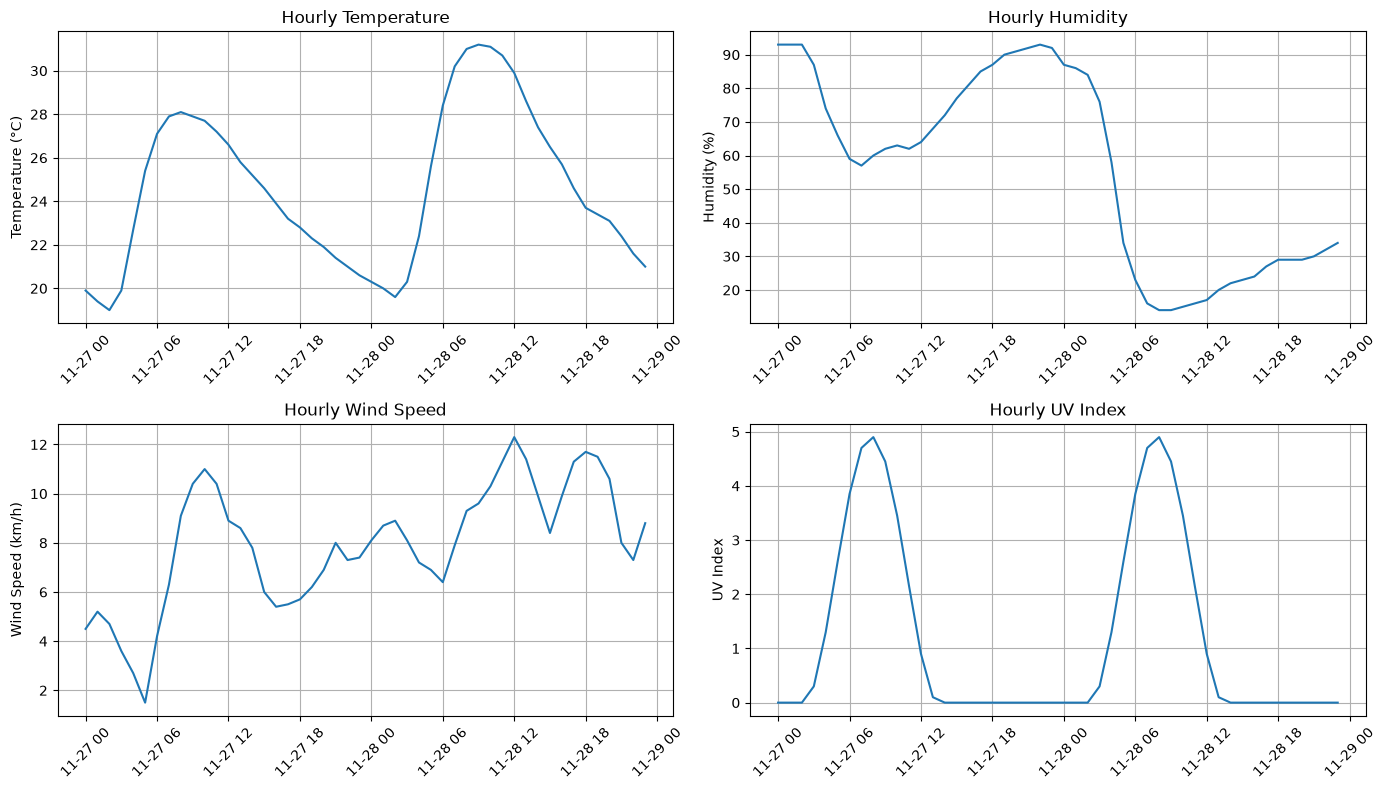

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Temperature
axes[0, 0].plot(weather_df.index, weather_df["temperature_2m"])
axes[0, 0].set_title("Hourly Temperature")
axes[0, 0].set_ylabel("Temperature (°C)")

# Humidity
axes[0, 1].plot(weather_df.index, weather_df["relative_humidity_2m"])
axes[0, 1].set_title("Hourly Humidity")
axes[0, 1].set_ylabel("Humidity (%)")

# Wind speed
axes[1, 0].plot(weather_df.index, weather_df["wind_speed_10m"])
axes[1, 0].set_title("Hourly Wind Speed")
axes[1, 0].set_ylabel("Wind Speed (km/h)")

# UV index
axes[1, 1].plot(weather_df.index, weather_df["uv_index"])
axes[1, 1].set_title("Hourly UV Index")
axes[1, 1].set_ylabel("UV Index")

for ax in axes.flat:
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True)

plt.tight_layout()

# Save the existing EDA visualization
plot_path = output_dir / "weather_overview_karachi.png"

fig.savefig(
    plot_path,
    dpi=150,
    bbox_inches="tight"
)

print(f"Plot saved successfully: {plot_path}")
plt.show()

In [18]:
# Historical Forecast API
historical_url = "https://historical-forecast-api.open-meteo.com/v1/forecast"

historical_params = {
    "latitude": 24.86,
    "longitude": 67.01,
    "start_date": "2026-11-20",
    "end_date": "2026-11-26",
    "hourly": (
        "temperature_2m,"
        "relative_humidity_2m,"
        "precipitation,"
        "precipitation_probability,"
        "wind_speed_10m,"
        "wind_direction_10m,"
        "uv_index,"
        "is_day"
    ),
    "temperature_unit": "celsius",
    "wind_speed_unit": "kmh",
    "precipitation_unit": "mm",
    "timezone": "UTC",
}

historical_response = requests.get(
    historical_url,
    params=historical_params,
    timeout=30
)

historical_response.raise_for_status()

historical_data = historical_response.json()

print("Historical API request successful!")
print("Available sections:", historical_data.keys())

Historical API request successful!
Available sections: dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])


In [19]:
# Extract the hourly section
historical_hourly = historical_data["hourly"]

# Check available variables
print("Available hourly variables:")
print(historical_hourly.keys())

# Check the number of timestamps
print("\nNumber of timestamps:", len(historical_hourly["time"]))

# Check the number of values in each variable
print("\nValues per variable:")

for column, values in historical_hourly.items():
    print(f"{column}: {len(values)} values")

Available hourly variables:
dict_keys(['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'precipitation_probability', 'wind_speed_10m', 'wind_direction_10m', 'uv_index', 'is_day'])

Number of timestamps: 168

Values per variable:
time: 168 values
temperature_2m: 168 values
relative_humidity_2m: 168 values
precipitation: 168 values
precipitation_probability: 168 values
wind_speed_10m: 168 values
wind_direction_10m: 168 values
uv_index: 168 values
is_day: 168 values


In [20]:
# Convert hourly JSON data into a Pandas DataFrame
historical_df = pd.DataFrame(historical_hourly)

# Convert time column into proper datetime format
historical_df["time"] = pd.to_datetime(
    historical_df["time"],
    utc=True
)

# Set time as the DataFrame index
historical_df = historical_df.set_index("time")

# Display the first five records
historical_df.head()

,temperature_2m,relative_humidity_2m,precipitation,precipitation_probability,wind_speed_10m,wind_direction_10m,uv_index,is_day
time,,,,,,,,
2026-11-20 00:00:00+00:00,20.5,39,0.0,0,9.9,27,0.00,0
2026-11-20 01:00:00+00:00,20.5,38,0.0,0,10.1,27,0.00,0
2026-11-20 02:00:00+00:00,20.6,36,0.0,0,10.0,26,0.00,1
2026-11-20 03:00:00+00:00,21.8,32,0.0,0,9.1,27,0.35,1
2026-11-20 04:00:00+00:00,24.2,27,0.0,0,7.0,26,1.45,1


In [21]:
# Check dataset dimensions
print("Dataset shape:", historical_df.shape)

# Check whether timestamps are sorted
print("\nTimestamps sorted:",
      historical_df.index.is_monotonic_increasing)

# Check duplicate timestamps
print("Duplicate timestamps:",
      historical_df.index.duplicated().sum())

# Check missing values
print("\nMissing values:")
print(historical_df.isnull().sum())

# Check numerical statistics
print("\nStatistical summary:")
historical_df.describe()

Dataset shape: (168, 8)

Timestamps sorted: True
Duplicate timestamps: 0

Missing values:
temperature_2m               0
relative_humidity_2m         0
precipitation                0
precipitation_probability    0
wind_speed_10m               0
wind_direction_10m           0
uv_index                     0
is_day                       0
dtype: int64

Statistical summary:


,temperature_2m,relative_humidity_2m,precipitation,precipitation_probability,wind_speed_10m,wind_direction_10m,uv_index,is_day
count,168.000000,168.000000,168.0,168.0,168.000000,168.000000,168.000000,168.000000
mean,24.406548,45.904762,0.0,0.0,7.377381,157.101190,1.226786,0.458333
std,3.815429,23.456990,0.0,0.0,2.496721,131.239811,1.782524,0.499750
min,18.000000,15.000000,0.0,0.0,0.900000,3.000000,0.000000,0.000000
25%,21.025000,26.000000,0.0,0.0,5.600000,30.500000,0.000000,0.000000
50%,23.850000,39.000000,0.0,0.0,7.400000,92.000000,0.000000,0.000000
75%,27.800000,63.500000,0.0,0.0,9.100000,298.250000,2.350000,1.000000
max,31.200000,94.000000,0.0,0.0,12.600000,358.000000,5.150000,1.000000


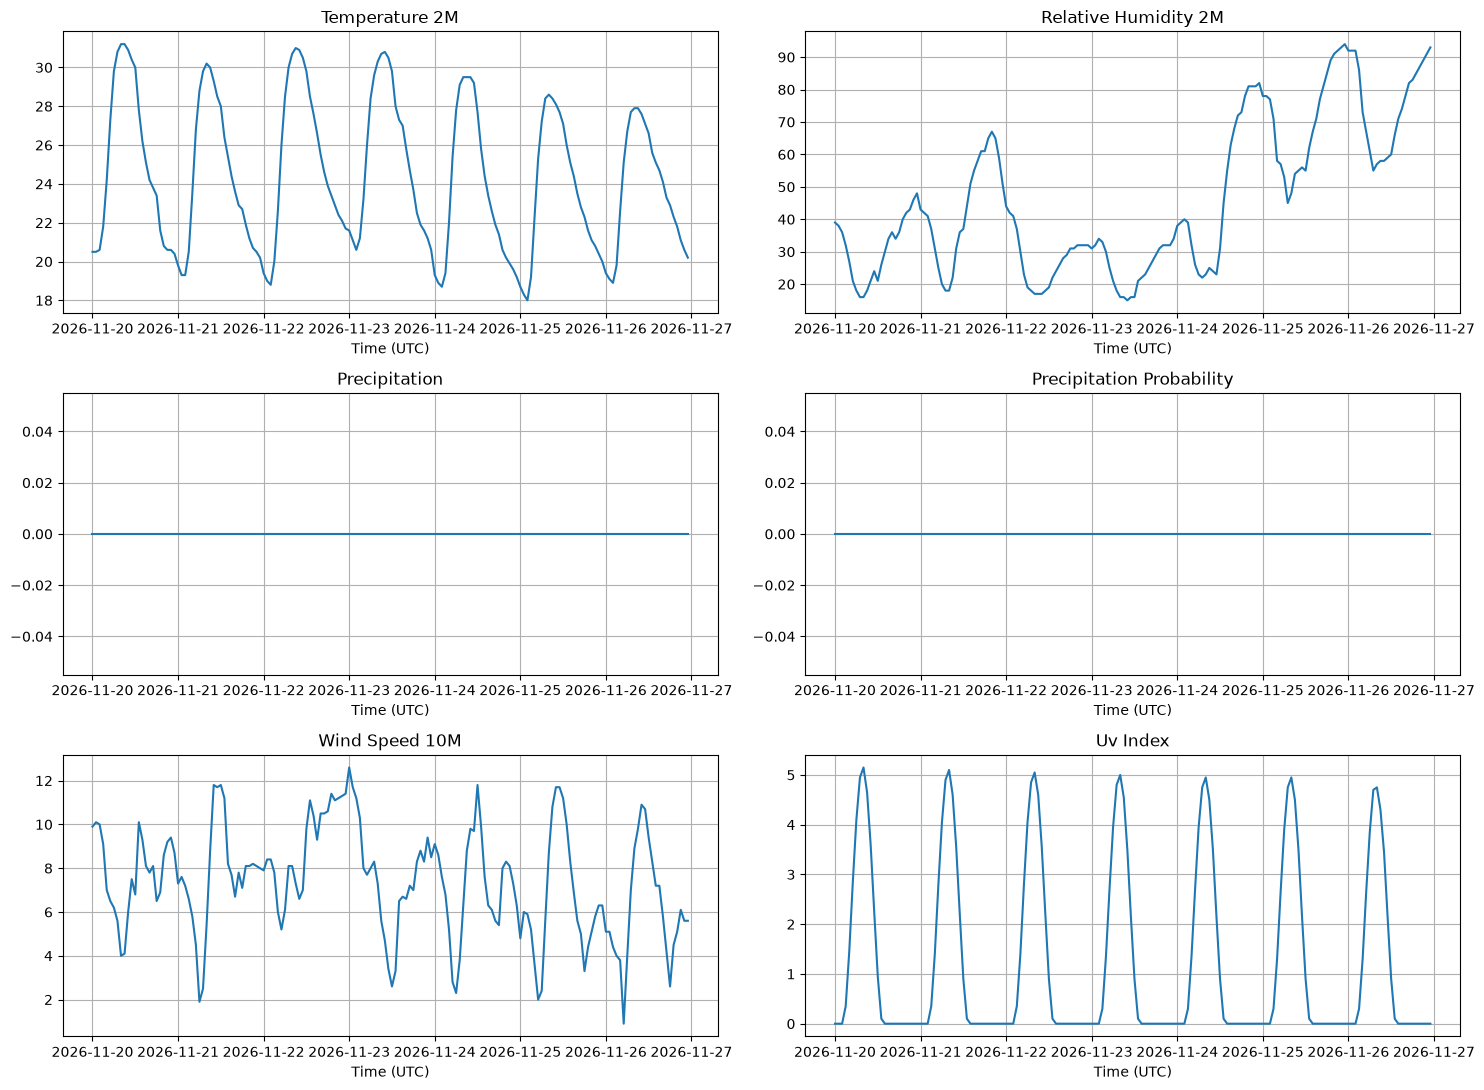

In [22]:
# Select the weather variables for visualization
columns_to_plot = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "precipitation_probability",
    "wind_speed_10m",
    "uv_index"
]

# Create a 3-row, 2-column figure
fig, axes = plt.subplots(3, 2, figsize=(15, 11))

# Plot each variable
for column, ax in zip(columns_to_plot, axes.flatten()):
    ax.plot(historical_df.index, historical_df[column])
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Time (UTC)")
    ax.grid(True)

# Improve spacing
fig.tight_layout()

# Save visualization
fig.savefig(
    output_dir / "historical_weather_overview_karachi.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [23]:
# Investigate precipitation statistics
precipitation_summary = historical_df[
    ["precipitation", "precipitation_probability"]
].agg(["min", "max", "mean", "sum", "nunique"])

print("Precipitation summary:")
display(precipitation_summary)

# Count records where precipitation is greater than zero
print("\nRecords with precipitation:")
print((historical_df["precipitation"] > 0).sum())

# Count records where rain probability is greater than zero
print("\nRecords with rain probability:")
print((historical_df["precipitation_probability"] > 0).sum())

Precipitation summary:


,precipitation,precipitation_probability
min,0.0,0.0
max,0.0,0.0
mean,0.0,0.0
sum,0.0,0.0
nunique,1.0,1.0



Records with precipitation:
0

Records with rain probability:
0


In [24]:
# Copy the existing parameters so we don't overwrite our original request
rain_check_params = historical_params.copy()

# Change only the requested date range
rain_check_params["start_date"] = "2026-08-01"
rain_check_params["end_date"] = "2026-08-07"

# Request historical weather for the new period
rain_response = requests.get(
    historical_url,
    params=rain_check_params,
    timeout=30
)

rain_response.raise_for_status()

rain_data = rain_response.json()

# Convert the hourly response into a DataFrame
rain_df = pd.DataFrame(rain_data["hourly"])

rain_df["time"] = pd.to_datetime(rain_df["time"], utc=True)
rain_df = rain_df.set_index("time")

# Check rainfall statistics
print("Dataset shape:", rain_df.shape)

print("\nPrecipitation summary:")
display(
    rain_df[
        ["precipitation", "precipitation_probability"]
    ].agg(["min", "max", "mean", "sum", "nunique"])
)

print(
    "\nHours with precipitation:",
    (rain_df["precipitation"] > 0).sum()
)

print(
    "Hours with rain probability:",
    (rain_df["precipitation_probability"] > 0).sum()
)

Dataset shape: (168, 8)

Precipitation summary:


,precipitation,precipitation_probability
min,0.00000,0.000000
max,0.20000,65.000000
mean,0.01369,3.613095
sum,2.30000,607.000000
nunique,3.00000,22.000000



Hours with precipitation: 21
Hours with rain probability: 46


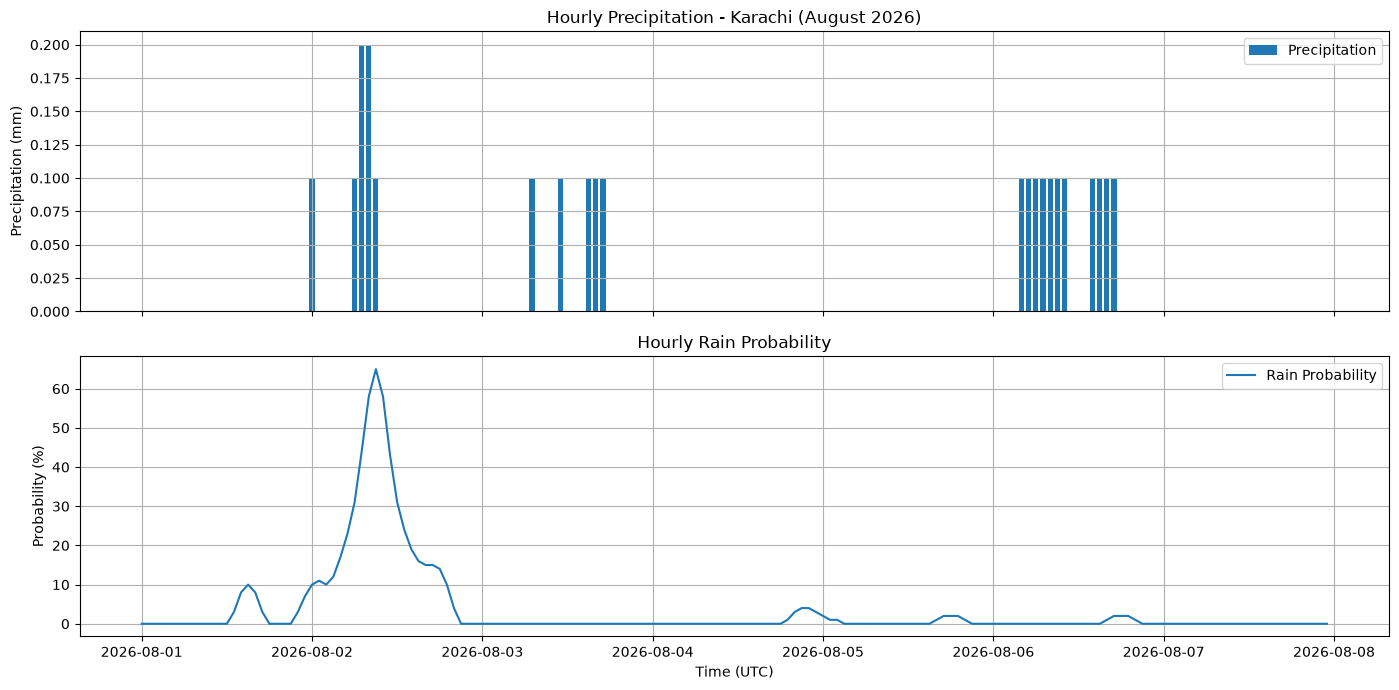

In [25]:
# Create two plots for rainfall analysis
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 7),
    sharex=True
)

# Plot hourly precipitation
axes[0].bar(
    rain_df.index,
    rain_df["precipitation"],
    width=0.03,
    label="Precipitation"
)

axes[0].set_title("Hourly Precipitation - Karachi (August 2026)")
axes[0].set_ylabel("Precipitation (mm)")
axes[0].grid(True)
axes[0].legend()

# Plot hourly rain probability
axes[1].plot(
    rain_df.index,
    rain_df["precipitation_probability"],
    label="Rain Probability"
)

axes[1].set_title("Hourly Rain Probability")
axes[1].set_xlabel("Time (UTC)")
axes[1].set_ylabel("Probability (%)")
axes[1].grid(True)
axes[1].legend()

# Improve layout
fig.tight_layout()

plt.show()

In [26]:
# Calculate daily rainfall statistics
daily_rain = rain_df.resample("D").agg(
    total_precipitation=("precipitation", "sum"),
    max_rain_probability=("precipitation_probability", "max"),
    rainy_hours=("precipitation", lambda values: (values > 0).sum())
)

# Display the daily summary
display(daily_rain)

,total_precipitation,max_rain_probability,rainy_hours
time,,,
2026-08-01 00:00:00+00:00,0.0,10,0
2026-08-02 00:00:00+00:00,0.7,65,5
2026-08-03 00:00:00+00:00,0.5,0,5
2026-08-04 00:00:00+00:00,0.0,4,0
2026-08-05 00:00:00+00:00,0.0,2,0
2026-08-06 00:00:00+00:00,1.1,2,11
2026-08-07 00:00:00+00:00,0.0,0,0


In [27]:
# Select only hours where rainfall was recorded
rainy_records = rain_df[
    rain_df["precipitation"] > 0
][
    ["precipitation", "precipitation_probability"]
]

# Display all rainy hours
display(rainy_records)

# Check whether any rainy hour has zero rain probability
print(
    "\nRainy hours with zero probability:",
    (
        (rainy_records["precipitation_probability"] == 0)
    ).sum()
)

,precipitation,precipitation_probability
time,,
2026-08-02 00:00:00+00:00,0.1,10
2026-08-02 06:00:00+00:00,0.1,31
2026-08-02 07:00:00+00:00,0.2,44
2026-08-02 08:00:00+00:00,0.2,58
2026-08-02 09:00:00+00:00,0.1,65
2026-08-03 07:00:00+00:00,0.1,0
2026-08-03 11:00:00+00:00,0.1,0
2026-08-03 15:00:00+00:00,0.1,0
2026-08-03 16:00:00+00:00,0.1,0



Rainy hours with zero probability: 14


In [28]:
# Find rainfall above the probability threshold
above_threshold = rainy_records[
    rainy_records["precipitation"] > 0.1
]

# Check records above 0.1 mm with zero probability
unexpected_records = above_threshold[
    above_threshold["precipitation_probability"] == 0
]

print("Rainy records:", len(rainy_records))
print("Records above 0.1 mm:", len(above_threshold))
print(
    "Records above 0.1 mm with zero probability:",
    len(unexpected_records)
)

display(unexpected_records)

Rainy records: 21
Records above 0.1 mm: 2
Records above 0.1 mm with zero probability: 0


,precipitation,precipitation_probability
time,,


In [29]:
# Inspect our historical API configuration
print("Historical API endpoint:")
print(historical_url)

print("\nHistorical API parameters:")
for key, value in historical_params.items():
    print(f"{key}: {value}")

Historical API endpoint:
https://historical-forecast-api.open-meteo.com/v1/forecast

Historical API parameters:
latitude: 24.86
longitude: 67.01
start_date: 2026-11-20
end_date: 2026-11-26
hourly: temperature_2m,relative_humidity_2m,precipitation,precipitation_probability,wind_speed_10m,wind_direction_10m,uv_index,is_day
temperature_unit: celsius
wind_speed_unit: kmh
precipitation_unit: mm
timezone: UTC


In [30]:
# Update the historical date range to one year
historical_params["start_date"] = "2025-11-27"
historical_params["end_date"] = "2026-11-26"

print("Start date:", historical_params["start_date"])
print("End date:", historical_params["end_date"])

Start date: 2025-11-27
End date: 2026-11-26


In [31]:
# Request one year of historical weather data
year_response = requests.get(
    historical_url,
    params=historical_params,
    timeout=60
)

# Check for HTTP errors
year_response.raise_for_status()

# Convert JSON response into a Python dictionary
year_data = year_response.json()

print("Historical data downloaded successfully!")
print("Available sections:", year_data.keys())

Historical data downloaded successfully!
Available sections: dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])


In [32]:
# Extract hourly weather observations
yearly_df = pd.DataFrame(year_data["hourly"])

# Convert time into UTC datetime
yearly_df["time"] = pd.to_datetime(
    yearly_df["time"],
    utc=True
)

# Set timestamp as DataFrame index
yearly_df = yearly_df.set_index("time")

# Display first five records
yearly_df.head()

,temperature_2m,relative_humidity_2m,precipitation,precipitation_probability,wind_speed_10m,wind_direction_10m,uv_index,is_day
time,,,,,,,,
2025-11-27 00:00:00+00:00,18.5,39,0.0,0,10.8,15,0.0,0
2025-11-27 01:00:00+00:00,18.3,40,0.0,0,11.8,11,0.0,0
2025-11-27 02:00:00+00:00,18.4,39,0.0,0,13.2,14,0.0,1
2025-11-27 03:00:00+00:00,19.4,36,0.0,0,13.0,18,0.3,1
2025-11-27 04:00:00+00:00,21.5,30,0.0,0,12.2,22,1.3,1


In [33]:
print("Dataset shape:", yearly_df.shape)

print("\nStart timestamp:")
print(yearly_df.index.min())

print("\nEnd timestamp:")
print(yearly_df.index.max())

print("\nMissing values:")
print(yearly_df.isnull().sum())

print("\nDuplicate timestamps:")
print(yearly_df.index.duplicated().sum())

Dataset shape: (8760, 8)

Start timestamp:
2025-11-27 00:00:00+00:00

End timestamp:
2026-11-26 23:00:00+00:00

Missing values:
temperature_2m               0
relative_humidity_2m         0
precipitation                0
precipitation_probability    0
wind_speed_10m               0
wind_direction_10m           0
uv_index                     0
is_day                       0
dtype: int64

Duplicate timestamps:
0


In [34]:
# Calculate time difference between consecutive records
time_gaps = yearly_df.index.to_series().diff()

print("Time interval distribution:")
print(time_gaps.value_counts())

print("\nUnexpected time gaps:")
print(time_gaps[time_gaps != pd.Timedelta(hours=1)].dropna())

Time interval distribution:
time
0 days 01:00:00    8759
Name: count, dtype: int64

Unexpected time gaps:
Series([], Name: time, dtype: timedelta64[us])


In [35]:
# Define the dataset output path
output_path = project_root / "data" / "historical_weather_karachi.parquet"

# Save the one-year dataset
yearly_df.to_parquet(output_path)

print("Dataset saved successfully!")
print("File location:", output_path)
print("Dataset shape:", yearly_df.shape)

Dataset saved successfully!
File location: /home/musman/Desktop/ShinePearl/AgentWeather/data/historical_weather_karachi.parquet
Dataset shape: (8760, 8)


In [36]:
saved_df = pd.read_parquet(output_path)

print("Shape:", saved_df.shape)
print("Missing values:", saved_df.isnull().sum().sum())
print("Date range:", saved_df.index.min(), "to", saved_df.index.max())

Shape: (8760, 8)
Missing values: 0
Date range: 2025-11-27 00:00:00+00:00 to 2026-11-26 23:00:00+00:00


In [37]:

from datetime import datetime, timedelta, timezone

# OpenWeather historical air pollution endpoint
aqi_url = "https://api.openweathermap.org/data/2.5/air_pollution/history"

# Define a 24-hour UTC window
end_time = datetime.now(timezone.utc)
start_time = end_time - timedelta(hours=24)

# Convert dates to Unix timestamps
aqi_params = {
    "lat": 24.86,
    "lon": 67.01,
    "start": int(start_time.timestamp()),
    "end": int(end_time.timestamp()),
    "appid": api_key,
}

# Send request
aqi_response = requests.get(
    aqi_url,
    params=aqi_params,
    timeout=30
)

# Check response
print("HTTP Status:", aqi_response.status_code)

aqi_response.raise_for_status()

aqi_data = aqi_response.json()

print("Response keys:", aqi_data.keys())
print("Number of records:", len(aqi_data.get("list", [])))

# Inspect one record
if aqi_data.get("list"):
    print("First AQI record:")
    print(aqi_data["list"][0])
else:
    print("No historical AQI records returned.")


HTTP Status: 200
Response keys: dict_keys(['coord', 'list'])
Number of records: 24
First AQI record:
{'main': {'aqi': 3}, 'components': {'co': 159.86, 'no': 0, 'no2': 0.06, 'o3': 99.73, 'so2': 0.59, 'pm2_5': 39.32, 'pm10': 92.35, 'nh3': 0}, 'dt': 1795712400}


In [38]:
# Convert API records into a DataFrame
aqi_df = pd.json_normalize(aqi_data["list"])

# Convert Unix timestamps into UTC datetime
aqi_df["dt"] = pd.to_datetime(
    aqi_df["dt"],
    unit="s",
    utc=True
)

# Set timestamp as the index
aqi_df = aqi_df.set_index("dt")

# Display the data
display(aqi_df.head())

# Inspect dataset information
print("Dataset shape:", aqi_df.shape)
print("\nColumns:")
print(aqi_df.columns.tolist())

print("\nMissing values:")
print(aqi_df.isnull().sum())

,main.aqi,components.co,components.no,components.no2,components.o3,components.so2,components.pm2_5,components.pm10,components.nh3
dt,,,,,,,,,
2026-11-26 17:00:00+00:00,3,159.86,0,0.06,99.73,0.59,39.32,92.35,0
2026-11-26 18:00:00+00:00,3,159.72,0,0.05,99.48,0.57,39.18,92.82,0
2026-11-26 19:00:00+00:00,3,159.40,0,0.05,99.22,0.55,39.00,93.28,0
2026-11-26 20:00:00+00:00,3,158.95,0,0.05,99.16,0.55,38.88,93.70,0
2026-11-26 21:00:00+00:00,3,158.32,0,0.05,99.17,0.54,38.72,93.95,0


Dataset shape: (24, 9)

Columns:
['main.aqi', 'components.co', 'components.no', 'components.no2', 'components.o3', 'components.so2', 'components.pm2_5', 'components.pm10', 'components.nh3']

Missing values:
main.aqi            0
components.co       0
components.no       0
components.no2      0
components.o3       0
components.so2      0
components.pm2_5    0
components.pm10     0
components.nh3      0
dtype: int64


In [39]:
# Define AQI dataset output path
aqi_output_path = project_root / "data" / "historical_aqi_karachi.parquet"

# Save AQI DataFrame
aqi_df.to_parquet(aqi_output_path)

print("AQI dataset saved successfully!")
print("File location:", aqi_output_path)
print("Dataset shape:", aqi_df.shape)

AQI dataset saved successfully!
File location: /home/musman/Desktop/ShinePearl/AgentWeather/data/historical_aqi_karachi.parquet
Dataset shape: (24, 9)


In [40]:
# Read the saved dataset
saved_aqi_df = pd.read_parquet(aqi_output_path)

print("Saved dataset shape:", saved_aqi_df.shape)
print("Date range:", saved_aqi_df.index.min(), "to", saved_aqi_df.index.max())

Saved dataset shape: (24, 9)
Date range: 2026-11-26 17:00:00+00:00 to 2026-11-27 16:00:00+00:00


In [41]:
from datetime import datetime, timedelta, timezone

# Define a 7-day test period
end_time = datetime(2026, 11, 26, 23, tzinfo=timezone.utc)
start_time = end_time - timedelta(days=7)

# Convert dates to Unix timestamps
start_timestamp = int(start_time.timestamp())
end_timestamp = int(end_time.timestamp())

# API parameters
test_params = {
    "lat": 24.86,
    "lon": 67.01,
    "start": start_timestamp,
    "end": end_timestamp,
    "appid": api_key
}

# Request historical AQI data
test_response = requests.get(
    aqi_url,
    params=test_params,
    timeout=30
)

print("HTTP Status:", test_response.status_code)

test_response.raise_for_status()

test_data = test_response.json()

print("Records received:", len(test_data.get("list", [])))

HTTP Status: 200
Records received: 169


In [42]:
# Convert API records into a DataFrame
test_aqi_df = pd.json_normalize(test_data["list"])

# Convert Unix timestamps to UTC
test_aqi_df["time"] = pd.to_datetime(
    test_aqi_df["dt"],
    unit="s",
    utc=True
)

# Set time as the index
test_aqi_df = test_aqi_df.set_index("time")

# Remove the original Unix timestamp column
test_aqi_df = test_aqi_df.drop(columns=["dt"])

# Sort records chronologically
test_aqi_df = test_aqi_df.sort_index()

# Inspect the dataset
print("Dataset shape:", test_aqi_df.shape)
print("First timestamp:", test_aqi_df.index.min())
print("Last timestamp:", test_aqi_df.index.max())

print("\nTime interval distribution:")
print(test_aqi_df.index.to_series().diff().value_counts())

print("\nMissing values:")
print(test_aqi_df.isnull().sum())

Dataset shape: (169, 9)
First timestamp: 2026-11-19 23:00:00+00:00
Last timestamp: 2026-11-26 23:00:00+00:00

Time interval distribution:
time
0 days 01:00:00    168
Name: count, dtype: int64

Missing values:
main.aqi            0
components.co       0
components.no       0
components.no2      0
components.o3       0
components.so2      0
components.pm2_5    0
components.pm10     0
components.nh3      0
dtype: int64


In [43]:

# Define the one-year historical period in UTC
start_time = datetime(2025, 11, 27, 0, tzinfo=timezone.utc)
end_time = datetime(2026, 11, 26, 23, tzinfo=timezone.utc)

# Convert dates to Unix timestamps
start_timestamp = int(start_time.timestamp())
end_timestamp = int(end_time.timestamp())

# Prepare API parameters
year_params = {
    "lat": 24.86,
    "lon": 67.01,
    "start": start_timestamp,
    "end": end_timestamp,
    "appid": api_key
}

# Request the complete year
year_response = requests.get(
    aqi_url,
    params=year_params,
    timeout=120
)

print("HTTP Status:", year_response.status_code)

year_response.raise_for_status()

year_data = year_response.json()

print("Records received:", len(year_data.get("list", [])))


HTTP Status: 200
Records received: 8280


In [44]:
# Convert API response into a DataFrame
yearly_aqi_df = pd.json_normalize(year_data["list"])

# Convert Unix timestamps to UTC
yearly_aqi_df["time"] = pd.to_datetime(
    yearly_aqi_df["dt"],
    unit="s",
    utc=True
)

# Set timestamp as index
yearly_aqi_df = yearly_aqi_df.set_index("time")

# Sort chronologically
yearly_aqi_df = yearly_aqi_df.sort_index()

# Inspect actual coverage
print("Total records:", len(yearly_aqi_df))
print("First timestamp:", yearly_aqi_df.index.min())
print("Last timestamp:", yearly_aqi_df.index.max())

# Check duplicate timestamps
print(
    "Duplicate timestamps:",
    yearly_aqi_df.index.duplicated().sum()
)

# Check hourly gaps
time_gaps = yearly_aqi_df.index.to_series().diff()

print("\nTime interval distribution:")
print(time_gaps.value_counts().head(10))

print("\nNon-hourly intervals:")
print(time_gaps[time_gaps != pd.Timedelta(hours=1)].dropna())

Total records: 8280
First timestamp: 2025-11-27 00:00:00+00:00
Last timestamp: 2026-11-26 23:00:00+00:00
Duplicate timestamps: 0

Time interval distribution:
time
0 days 01:00:00    8262
1 days 01:00:00      14
2 days 01:00:00       3
Name: count, dtype: int64

Non-hourly intervals:
time
2026-01-02 01:00:00+00:00   1 days 01:00:00
2026-01-29 01:00:00+00:00   1 days 01:00:00
2026-02-16 01:00:00+00:00   1 days 01:00:00
2026-02-19 01:00:00+00:00   1 days 01:00:00
2026-02-23 01:00:00+00:00   1 days 01:00:00
2026-03-02 01:00:00+00:00   1 days 01:00:00
2026-03-05 01:00:00+00:00   1 days 01:00:00
2026-04-07 01:00:00+00:00   1 days 01:00:00
2026-05-12 01:00:00+00:00   1 days 01:00:00
2026-05-20 01:00:00+00:00   1 days 01:00:00
2026-07-11 01:00:00+00:00   1 days 01:00:00
2026-08-26 01:00:00+00:00   1 days 01:00:00
2026-08-29 01:00:00+00:00   1 days 01:00:00
2026-09-06 01:00:00+00:00   2 days 01:00:00
2026-09-09 01:00:00+00:00   2 days 01:00:00
2026-11-16 01:00:00+00:00   1 days 01:00:00
2026-11

In [45]:
# Generate the complete expected hourly timeline
expected_index = pd.date_range(
    start=yearly_aqi_df.index.min(),
    end=yearly_aqi_df.index.max(),
    freq="h"
)

# Find timestamps absent from the API response
missing_timestamps = expected_index.difference(
    yearly_aqi_df.index
)

print("Expected timestamps:", len(expected_index))
print("Available timestamps:", len(yearly_aqi_df))
print("Missing timestamps:", len(missing_timestamps))

print("\nMissing timestamps:")
print(missing_timestamps)

Expected timestamps: 8760
Available timestamps: 8280
Missing timestamps: 480

Missing timestamps:
DatetimeIndex(['2026-01-01 01:00:00+00:00', '2026-01-01 02:00:00+00:00',
               '2026-01-01 03:00:00+00:00', '2026-01-01 04:00:00+00:00',
               '2026-01-01 05:00:00+00:00', '2026-01-01 06:00:00+00:00',
               '2026-01-01 07:00:00+00:00', '2026-01-01 08:00:00+00:00',
               '2026-01-01 09:00:00+00:00', '2026-01-01 10:00:00+00:00',
               ...
               '2026-11-18 15:00:00+00:00', '2026-11-18 16:00:00+00:00',
               '2026-11-18 17:00:00+00:00', '2026-11-18 18:00:00+00:00',
               '2026-11-18 19:00:00+00:00', '2026-11-18 20:00:00+00:00',
               '2026-11-18 21:00:00+00:00', '2026-11-18 22:00:00+00:00',
               '2026-11-18 23:00:00+00:00', '2026-11-19 00:00:00+00:00'],
              dtype='datetime64[us, UTC]', length=480, freq=None)


In [46]:
# Convert missing timestamps into a Series
missing_series = pd.Series(missing_timestamps)

# Identify where consecutive missing hours are separated
groups = missing_series.diff().ne(pd.Timedelta(hours=1)).cumsum()

# Group missing timestamps into continuous periods
missing_periods = (
    missing_series.groupby(groups)
    .agg(["min", "max", "count"])
)

missing_periods.columns = [
    "start_time",
    "end_time",
    "missing_hours"
]

print("Missing periods:", len(missing_periods))
display(missing_periods)

Missing periods: 17


,start_time,end_time,missing_hours
1,2026-01-01 01:00:00+00:00,2026-01-02 00:00:00+00:00,24
2,2026-01-28 01:00:00+00:00,2026-01-29 00:00:00+00:00,24
3,2026-02-15 01:00:00+00:00,2026-02-16 00:00:00+00:00,24
4,2026-02-18 01:00:00+00:00,2026-02-19 00:00:00+00:00,24
5,2026-02-22 01:00:00+00:00,2026-02-23 00:00:00+00:00,24
6,2026-03-01 01:00:00+00:00,2026-03-02 00:00:00+00:00,24
7,2026-03-04 01:00:00+00:00,2026-03-05 00:00:00+00:00,24
8,2026-04-06 01:00:00+00:00,2026-04-07 00:00:00+00:00,24
9,2026-05-11 01:00:00+00:00,2026-05-12 00:00:00+00:00,24
10,2026-05-19 01:00:00+00:00,2026-05-20 00:00:00+00:00,24


In [47]:
import time

recovered_records = []

for period_number, period in missing_periods.iterrows():

    start_timestamp = int(period["start_time"].timestamp())

    # Add one hour to include the final missing timestamp
    end_timestamp = int(
        (period["end_time"] + pd.Timedelta(hours=1)).timestamp()
    )

    params = {
        "lat": 24.86,
        "lon": 67.01,
        "start": start_timestamp,
        "end": end_timestamp,
        "appid": api_key
    }

    response = requests.get(
        aqi_url,
        params=params,
        timeout=30
    )

    response.raise_for_status()

    period_data = response.json()

    for record in period_data.get("list", []):

        timestamp = pd.to_datetime(
            record["dt"],
            unit="s",
            utc=True
        )

        row = {
            "dt": timestamp,
            "main.aqi": record["main"]["aqi"]
        }

        for pollutant, value in record["components"].items():
            row[f"components.{pollutant}"] = value

        recovered_records.append(row)

    print(
        f"Period {period_number}: "
        f"{len(period_data.get('list', []))} records retrieved"
    )

    time.sleep(0.2)

print("\nTotal recovered records:", len(recovered_records))

Period 1: 1 records retrieved
Period 2: 1 records retrieved
Period 3: 1 records retrieved
Period 4: 1 records retrieved
Period 5: 1 records retrieved
Period 6: 1 records retrieved
Period 7: 1 records retrieved
Period 8: 1 records retrieved
Period 9: 1 records retrieved
Period 10: 1 records retrieved
Period 11: 1 records retrieved
Period 12: 1 records retrieved
Period 13: 1 records retrieved
Period 14: 1 records retrieved
Period 15: 1 records retrieved
Period 16: 1 records retrieved
Period 17: 1 records retrieved

Total recovered records: 17


In [48]:
# Inspect the first missing period
first_period = missing_periods.iloc[0]

print("Requested start:", first_period["start_time"])
print("Requested end:", first_period["end_time"])
print("Expected missing hours:", first_period["missing_hours"])

# Inspect the actual record returned
print("\nActual recovered record:")
print(recovered_records[0])

Requested start: 2026-01-01 01:00:00+00:00
Requested end: 2026-01-02 00:00:00+00:00
Expected missing hours: 24

Actual recovered record:
{'dt': Timestamp('2026-01-02 01:00:00+0000', tz='UTC'), 'main.aqi': 4, 'components.co': 319.57, 'components.no': 0, 'components.no2': 1.03, 'components.o3': 113.09, 'components.so2': 7.72, 'components.pm2_5': 59.33, 'components.pm10': 113.28, 'components.nh3': 0.08}


In [49]:
# Compare requested timestamps with the returned timestamp
print("All timestamps returned for period 1:")

for record in recovered_records:
    print(record["dt"])

All timestamps returned for period 1:
2026-01-02 01:00:00+00:00
2026-01-29 01:00:00+00:00
2026-02-16 01:00:00+00:00
2026-02-19 01:00:00+00:00
2026-02-23 01:00:00+00:00
2026-03-02 01:00:00+00:00
2026-03-05 01:00:00+00:00
2026-04-07 01:00:00+00:00
2026-05-12 01:00:00+00:00
2026-05-20 01:00:00+00:00
2026-07-11 01:00:00+00:00
2026-08-26 01:00:00+00:00
2026-08-29 01:00:00+00:00
2026-09-06 01:00:00+00:00
2026-09-09 01:00:00+00:00
2026-11-16 01:00:00+00:00
2026-11-19 01:00:00+00:00


In [50]:

# Diagnostic: test one missing AQI period

period = missing_periods.iloc[0]

# Requested missing interval
missing_start = period["start_time"]
missing_end = period["end_time"]

# Expand the request by two hours on each side
request_start = missing_start - pd.Timedelta(hours=2)
request_end = missing_end + pd.Timedelta(hours=2)

test_params = {
    "lat": 24.86,
    "lon": 67.01,
    "start": int(request_start.timestamp()),
    "end": int(request_end.timestamp()),
    "appid": api_key
}

print("Missing interval:", missing_start, "to", missing_end)
print("API request interval:", request_start, "to", request_end)

# Make one API request
test_response = requests.get(
    aqi_url,
    params=test_params,
    timeout=30
)

print("\nHTTP status:", test_response.status_code)
print("Request parameters:", {
    k: v for k, v in test_params.items() if k != "appid"
})

test_response.raise_for_status()

test_data = test_response.json()
test_records = test_data.get("list", [])

print("\nRecords returned:", len(test_records))

# Display every returned timestamp
for record in test_records:
    timestamp = pd.to_datetime(
        record["dt"], unit="s", utc=True
    )
    print(timestamp, "| AQI:", record["main"]["aqi"])


Missing interval: 2026-01-01 01:00:00+00:00 to 2026-01-02 00:00:00+00:00
API request interval: 2025-12-31 23:00:00+00:00 to 2026-01-02 02:00:00+00:00

HTTP status: 200
Request parameters: {'lat': 24.86, 'lon': 67.01, 'start': 1767222000, 'end': 1767319200}

Records returned: 4
2025-12-31 23:00:00+00:00 | AQI: 3
2026-01-01 00:00:00+00:00 | AQI: 3
2026-01-02 01:00:00+00:00 | AQI: 4
2026-01-02 02:00:00+00:00 | AQI: 4


In [51]:

# 1. Create a complete hourly timeline
full_index = pd.date_range(
    start=yearly_aqi_df.index.min(),
    end=yearly_aqi_df.index.max(),
    freq="h"
)

# 2. Reindex without inventing AQI measurements
aqi_complete_df = yearly_aqi_df.reindex(full_index)

# 3. Validate the result
print("Dataset shape:", aqi_complete_df.shape)
print("\nMissing values:")
print(aqi_complete_df.isna().sum())

print("\nMissing AQI hours:",
      aqi_complete_df["main.aqi"].isna().sum())

print("\nDate range:",
      aqi_complete_df.index.min(),
      "to",
      aqi_complete_df.index.max())

# 4. Save the validated dataset
aqi_complete_path = (
    project_root / "data" / "historical_aqi_karachi_complete.parquet"
)

aqi_complete_df.to_parquet(aqi_complete_path)

print("\nSaved:", aqi_complete_path)


Dataset shape: (8760, 10)

Missing values:
dt                  480
main.aqi            480
components.co       480
components.no       480
components.no2      480
components.o3       480
components.so2      480
components.pm2_5    480
components.pm10     480
components.nh3      480
dtype: int64

Missing AQI hours: 480

Date range: 2025-11-27 00:00:00+00:00 to 2026-11-26 23:00:00+00:00

Saved: /home/musman/Desktop/ShinePearl/AgentWeather/data/historical_aqi_karachi_complete.parquet


In [52]:

# The datetime index is our source of truth.
# Remove the duplicate datetime column.
aqi_complete_df = aqi_complete_df.drop(columns=["dt"])

# Verify
print("Shape:", aqi_complete_df.shape)
print("\nMissing values:")
print(aqi_complete_df.isnull().sum())

# Save the cleaned dataset
aqi_complete_df.to_parquet(
    project_root / "data" / "historical_aqi_karachi_complete.parquet"
)

print("\nCleaned AQI dataset saved successfully!")


Shape: (8760, 9)

Missing values:
main.aqi            480
components.co       480
components.no       480
components.no2      480
components.o3       480
components.so2      480
components.pm2_5    480
components.pm10     480
components.nh3      480
dtype: int64

Cleaned AQI dataset saved successfully!


In [53]:
# Make copies so the original datasets remain unchanged
weather_df = saved_df.copy()
aqi_df = aqi_complete_df.copy()

# Ensure both indexes are UTC datetime indexes
weather_df.index = pd.to_datetime(weather_df.index, utc=True)
aqi_df.index = pd.to_datetime(aqi_df.index, utc=True)

# Sort both datasets chronologically
weather_df = weather_df.sort_index()
aqi_df = aqi_df.sort_index()

# Merge using hourly timestamps
combined_df = weather_df.join(
    aqi_df,
    how="left",
    validate="one_to_one"
)

# Inspect the merged dataset
print("Combined dataset shape:", combined_df.shape)

print("\nDate range:")
print(combined_df.index.min(), "to", combined_df.index.max())

print("\nMissing values:")
print(combined_df.isnull().sum())

print("\nFirst five rows:")
display(combined_df.head())

Combined dataset shape: (8760, 17)

Date range:
2025-11-27 00:00:00+00:00 to 2026-11-26 23:00:00+00:00

Missing values:
temperature_2m                 0
relative_humidity_2m           0
precipitation                  0
precipitation_probability      0
wind_speed_10m                 0
wind_direction_10m             0
uv_index                       0
is_day                         0
main.aqi                     480
components.co                480
components.no                480
components.no2               480
components.o3                480
components.so2               480
components.pm2_5             480
components.pm10              480
components.nh3               480
dtype: int64

First five rows:


,temperature_2m,relative_humidity_2m,precipitation,precipitation_probability,wind_speed_10m,wind_direction_10m,uv_index,is_day,main.aqi,components.co,components.no,components.no2,components.o3,components.so2,components.pm2_5,components.pm10,components.nh3
time,,,,,,,,,,,,,,,,,
2025-11-27 00:00:00+00:00,18.5,39,0.0,0,10.8,15,0.0,0,4.0,252.05,0.00,1.45,133.53,9.07,47.15,101.69,2.21
2025-11-27 01:00:00+00:00,18.3,40,0.0,0,11.8,11,0.0,0,3.0,244.21,0.00,1.36,131.59,8.58,45.67,99.20,2.17
2025-11-27 02:00:00+00:00,18.4,39,0.0,0,13.2,14,0.0,1,3.0,237.88,0.00,1.29,131.06,8.18,45.04,97.99,2.13
2025-11-27 03:00:00+00:00,19.4,36,0.0,0,13.0,18,0.3,1,3.0,233.67,0.01,1.57,132.11,7.87,45.50,98.88,2.10
2025-11-27 04:00:00+00:00,21.5,30,0.0,0,12.2,22,1.3,1,4.0,231.66,0.06,1.86,133.91,7.73,47.09,102.44,2.11


In [54]:
# Make a copy of the merged dataset
final_df = combined_df.copy()

# AQI and pollutant columns
aqi_columns = [
    "main.aqi",
    "components.co",
    "components.no",
    "components.no2",
    "components.o3",
    "components.so2",
    "components.pm2_5",
    "components.pm10",
    "components.nh3"
]

# Record which rows originally had missing AQI data
final_df["aqi_was_missing"] = final_df["main.aqi"].isna()

# Fill missing values using median
for column in aqi_columns:

    median_value = final_df[column].median()

    if column == "main.aqi":
        median_value = round(median_value)

    final_df[column] = final_df[column].fillna(median_value)

# Verify missing values
print("Missing values after imputation:")
print(final_df[aqi_columns].isnull().sum())

print("\nFinal dataset shape:", final_df.shape)

print("\nOriginal missing AQI rows:",
      final_df["aqi_was_missing"].sum())

print("\nFinal dataset preview:")
display(final_df.head())

Missing values after imputation:
main.aqi            0
components.co       0
components.no       0
components.no2      0
components.o3       0
components.so2      0
components.pm2_5    0
components.pm10     0
components.nh3      0
dtype: int64

Final dataset shape: (8760, 18)

Original missing AQI rows: 480

Final dataset preview:


,temperature_2m,relative_humidity_2m,precipitation,precipitation_probability,wind_speed_10m,wind_direction_10m,uv_index,is_day,main.aqi,components.co,components.no,components.no2,components.o3,components.so2,components.pm2_5,components.pm10,components.nh3,aqi_was_missing
time,,,,,,,,,,,,,,,,,,
2025-11-27 00:00:00+00:00,18.5,39,0.0,0,10.8,15,0.0,0,4.0,252.05,0.00,1.45,133.53,9.07,47.15,101.69,2.21,False
2025-11-27 01:00:00+00:00,18.3,40,0.0,0,11.8,11,0.0,0,3.0,244.21,0.00,1.36,131.59,8.58,45.67,99.20,2.17,False
2025-11-27 02:00:00+00:00,18.4,39,0.0,0,13.2,14,0.0,1,3.0,237.88,0.00,1.29,131.06,8.18,45.04,97.99,2.13,False
2025-11-27 03:00:00+00:00,19.4,36,0.0,0,13.0,18,0.3,1,3.0,233.67,0.01,1.57,132.11,7.87,45.50,98.88,2.10,False
2025-11-27 04:00:00+00:00,21.5,30,0.0,0,12.2,22,1.3,1,4.0,231.66,0.06,1.86,133.91,7.73,47.09,102.44,2.11,False


In [55]:
# Save final historical dataset
final_path = (
    project_root
    / "data"
    / "historical_weather_aqi_karachi.parquet"
)

final_df.to_parquet(final_path)

print("Final dataset saved successfully!")
print("Location:", final_path)
print("Shape:", final_df.shape)

Final dataset saved successfully!
Location: /home/musman/Desktop/ShinePearl/AgentWeather/data/historical_weather_aqi_karachi.parquet
Shape: (8760, 18)


In [56]:
# Reload the saved dataset
final_df = pd.read_parquet(final_path)

print("DATA QUALITY REPORT")
print("=" * 40)

print("Dataset shape:", final_df.shape)

print("\nMissing values:")
print(final_df.isnull().sum())

print("\nImputed AQI records:",
      final_df["aqi_was_missing"].sum())

print("\nAQI distribution:")
print(final_df["main.aqi"].value_counts().sort_index())

print("\nDuplicate timestamps:",
      final_df.index.duplicated().sum())

print("\nDate range:")
print(final_df.index.min(), "to", final_df.index.max())

DATA QUALITY REPORT
Dataset shape: (8760, 18)

Missing values:
temperature_2m               0
relative_humidity_2m         0
precipitation                0
precipitation_probability    0
wind_speed_10m               0
wind_direction_10m           0
uv_index                     0
is_day                       0
main.aqi                     0
components.co                0
components.no                0
components.no2               0
components.o3                0
components.so2               0
components.pm2_5             0
components.pm10              0
components.nh3               0
aqi_was_missing              0
dtype: int64

Imputed AQI records: 480

AQI distribution:
main.aqi
1.0     159
2.0    1785
3.0    4192
4.0    2091
5.0     533
Name: count, dtype: int64

Duplicate timestamps: 0

Date range:
2025-11-27 00:00:00+00:00 to 2026-11-26 23:00:00+00:00


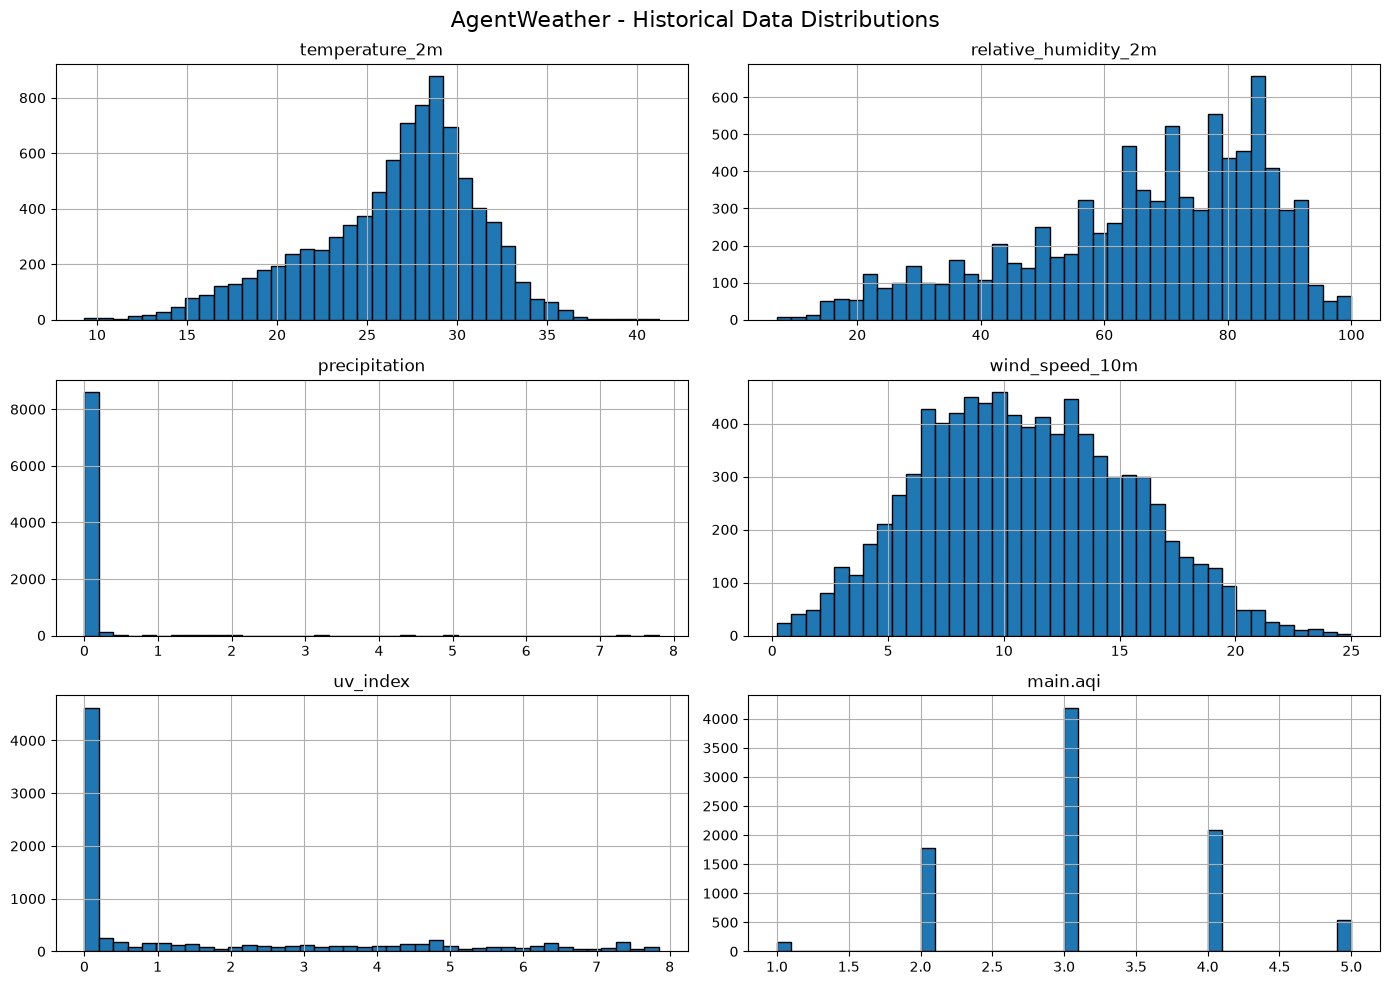

In [57]:
import matplotlib.pyplot as plt

# Select important weather variables
weather_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "uv_index",
    "main.aqi"
]

# Plot distributions
final_df[weather_columns].hist(
    figsize=(14, 10),
    bins=40,
    edgecolor="black"
)

plt.suptitle(
    "AgentWeather - Historical Data Distributions",
    fontsize=16
)

plt.tight_layout()
plt.show()

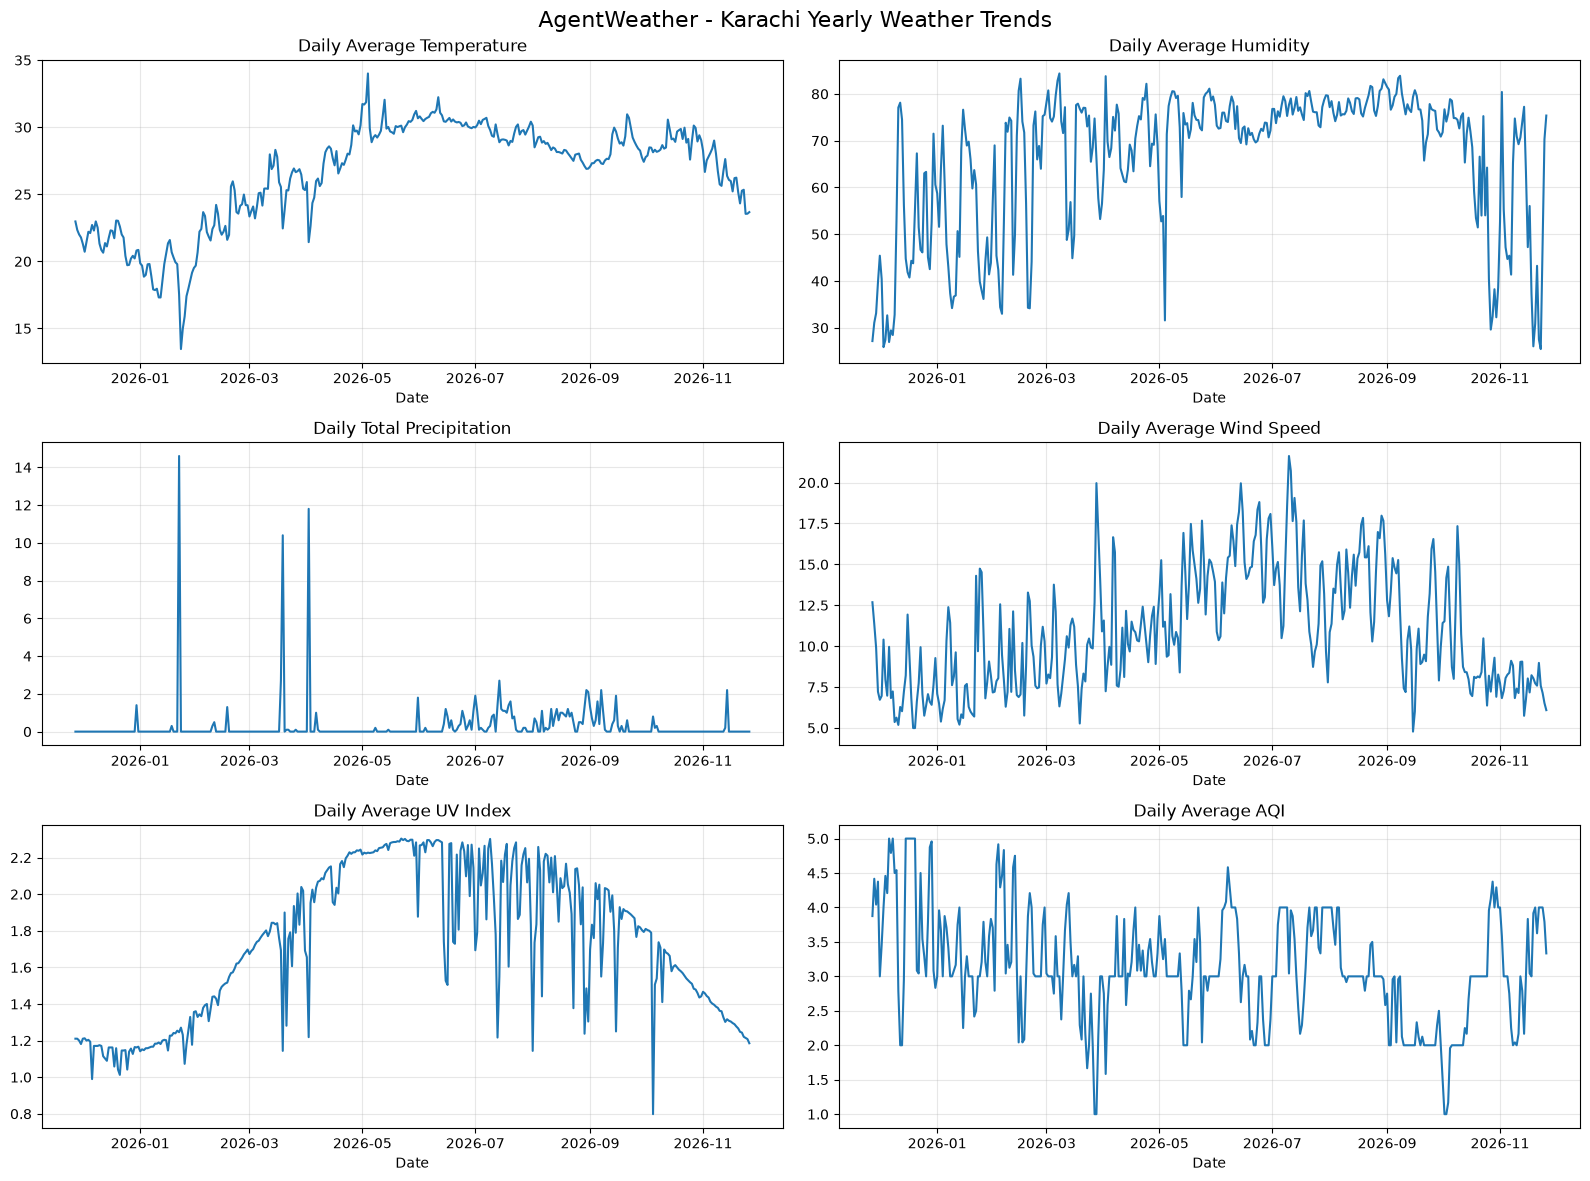

In [58]:
# Convert hourly data into daily averages
daily_df = final_df.resample("D").agg({
    "temperature_2m": "mean",
    "relative_humidity_2m": "mean",
    "precipitation": "sum",
    "wind_speed_10m": "mean",
    "uv_index": "mean",
    "main.aqi": "mean"
})

# Plot daily trends
fig, axes = plt.subplots(3, 2, figsize=(16, 12))

columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "uv_index",
    "main.aqi"
]

titles = [
    "Daily Average Temperature",
    "Daily Average Humidity",
    "Daily Total Precipitation",
    "Daily Average Wind Speed",
    "Daily Average UV Index",
    "Daily Average AQI"
]

for ax, column, title in zip(
    axes.flatten(), columns, titles
):
    ax.plot(daily_df.index, daily_df[column])
    ax.set_title(title)
    ax.set_xlabel("Date")
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "AgentWeather - Karachi Yearly Weather Trends",
    fontsize=16
)

plt.tight_layout()
plt.show()

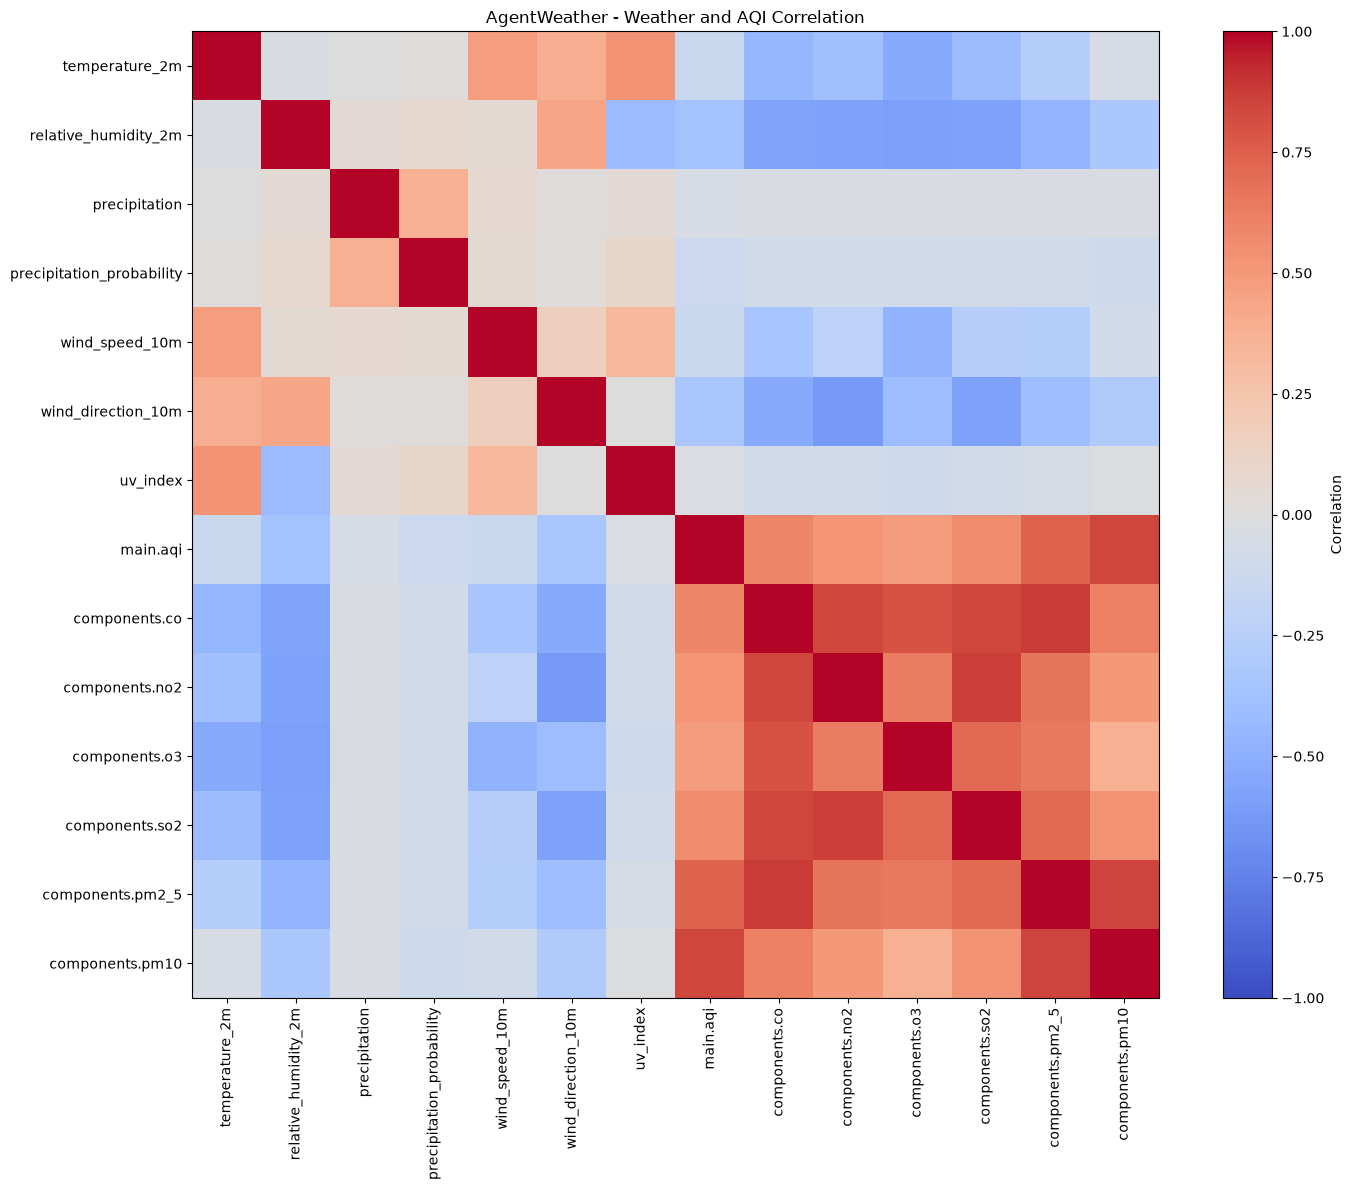

In [59]:
import matplotlib.pyplot as plt
import numpy as np

# Select numerical weather and AQI variables
correlation_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "precipitation_probability",
    "wind_speed_10m",
    "wind_direction_10m",
    "uv_index",
    "main.aqi",
    "components.co",
    "components.no2",
    "components.o3",
    "components.so2",
    "components.pm2_5",
    "components.pm10"
]

# Calculate correlation matrix
correlation_matrix = final_df[correlation_columns].corr()

# Plot correlation heatmap
fig, ax = plt.subplots(figsize=(15, 12))

image = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(correlation_columns)))
ax.set_yticks(range(len(correlation_columns)))

ax.set_xticklabels(
    correlation_columns,
    rotation=90
)

ax.set_yticklabels(correlation_columns)

plt.colorbar(image, label="Correlation")

plt.title("AgentWeather - Weather and AQI Correlation")

plt.tight_layout()
plt.show()

In [60]:
# Create a monthly summary
monthly_df = final_df.copy()

monthly_df["month"] = monthly_df.index.month

monthly_summary = monthly_df.groupby("month").agg({
    "temperature_2m": "mean",
    "relative_humidity_2m": "mean",
    "precipitation": "sum",
    "wind_speed_10m": "mean",
    "uv_index": "mean",
    "main.aqi": "mean"
})

monthly_summary.index = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

display(monthly_summary.round(2))

,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,uv_index,main.aqi
Jan,18.74,53.00,14.9,8.25,1.21,3.24
Feb,23.19,61.14,2.1,8.95,1.50,3.51
Mar,25.57,69.59,13.4,10.08,1.76,2.76
Apr,27.20,70.77,12.9,10.58,2.07,3.12
May,30.36,72.39,2.1,13.26,2.25,2.99
Jun,30.60,73.02,8.3,15.44,2.13,3.05
Jul,29.71,77.10,19.1,13.96,2.03,3.51
Aug,28.23,77.88,21.1,14.52,1.92,3.18
Sep,28.46,76.80,12.4,11.16,1.85,2.21
Oct,28.95,62.76,1.3,9.59,1.57,2.66


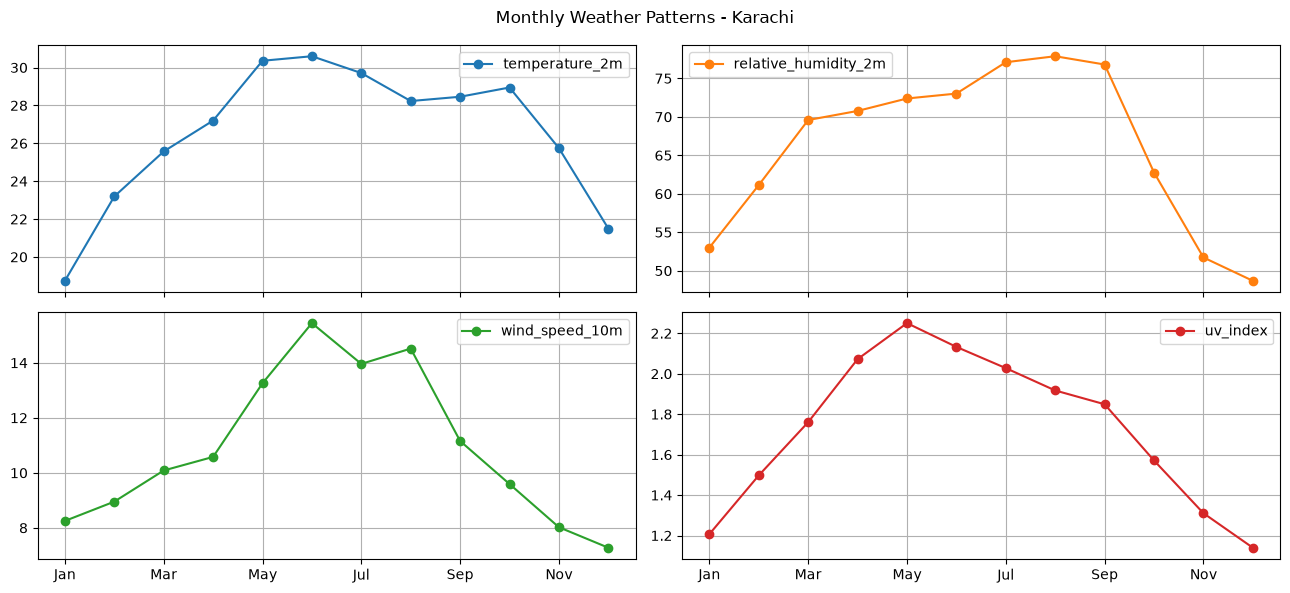

In [61]:
monthly_summary[
    ["temperature_2m", "relative_humidity_2m",
     "wind_speed_10m", "uv_index"]
].plot(
    figsize=(13, 6),
    marker="o",
    subplots=True,
    layout=(2, 2),
    title="Monthly Weather Patterns - Karachi",
    grid=True
)

plt.tight_layout()
plt.show()